# 04 - Testing the hypotheses H1-H12

Implements the tests from the research plan (section 5) with the data you have. Windows and events come from
`config/events.csv`, keyword lists from `config/keywords.json`, channel cohorts from `config/channel_groups.csv`.
Change those files, not the code, and **freeze them before you look at results** (pre-registration, plan section 6).

How to read the output
* Each section prints estimates and draws the series; the last cell collects every p-value in one table with
  **Holm-adjusted** p-values (12 hypotheses = multiple testing).
* Models: event windows use a **placebo test** (same statistic on random other days); interrupted time series use a
  Poisson regression with robust (HAC) errors and weekday dummies; keyword shifts use two-proportion tests
  (a lower bound on the real uncertainty - posts from the same channel and day are not independent).
* A section that lacks its prerequisites (a channel group, a date, an external file) says so and is skipped.
* Prerequisites I cannot provide: **OxCGRT stringency data** for H1 (download it yourself, see H1), **subscriber
  counts** for H4 (not exported), **X/Twitter data** for H7 (not testable with Telegram data).
* Confounders to keep in mind: channels join the data at different times, other events fall into the same windows, and
  daily counts have weekday and holiday patterns.

In [1]:
%matplotlib inline
import os, warnings
from datetime import date, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

from tg_ingestor.analysis import *

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

DATA = os.environ.get("TG_DATA", "../storage/raw")            # folder with the exported .csv / .parquet files
FIG = Path(os.environ.get("TG_FIGURES", "../storage/figures"))  # every plot / table is also saved here
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.25})
pl.Config.set_tbl_rows(40).set_tbl_cols(20).set_fmt_str_lengths(70)


def savefig(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

In [2]:
PHASES = load_phases(os.environ.get("TG_PHASES"))
EVENTS = load_events(os.environ.get("TG_EVENTS"))
KW = load_keywords(os.environ.get("TG_KEYWORDS"))
GROUPS = load_channel_groups(os.environ.get("TG_CHANNEL_GROUPS"))
df = load_corpus(DATA)
START, END = df["day"].min(), df["day"].max()
ev = {r["event"]: r["date"] for r in EVENTS.iter_rows(named=True)}
ALL_EVENT_DATES = list(ev.values())

# one boolean column per keyword list
df = df.with_columns([keyword_flag(terms).alias(f"kw_{name}") for name, terms in KW.items()])

RESULTS = []
def record(h, test, estimate, p=None, note=""):
    RESULTS.append({"hypothesis": h, "test": test, "estimate": estimate, "p": p, "note": note})

def series_for(frame, col="n"):
    """daily series for any subset of posts (zero-filled from the subset's first post to the end of the data)."""
    return to_series(daily_counts(frame, by=(), end=END), col, start=START, end=END)

def per_post(frame, col):
    n = series_for(frame, "n").replace(0, np.nan)
    return series_for(frame, col) / n

def group_frame(name):
    chans = channels_of(df, GROUPS.get(name, []))
    return df.filter(pl.col("channel").is_in(chans)), chans

print(f"{df.height:,} posts, {START} .. {END}")
print("events with a date:", ", ".join(ev))
print("channel groups:", {k: len(v) for k, v in GROUPS.items()} or "none defined (config/channel_groups.csv)")
print("keyword lists:", {k: len(v) for k, v in KW.items()})

869,307 posts, 2020-01-01 .. 2026-10-21
events with a date: leipzig_protest, reichstag_blockade, qanon_telegram_surge, us_inauguration, ukraine_invasion, reichsbuerger_raid, twitter_api_paywall, heizungsgesetz, hamas_attack, correctiv_report, dsa_enforcement, who_pandemic_agreement, telegram_ip_policy, snap_election
channel groups: {'qanon': 1}
keyword lists: {'covid_core': 3, 'covid_extended': 10, 'ukraine_core': 7, 'ukraine_extended': 7, 'antisemitic_h8': 2, 'remigration_h9': 3, 'who_h10': 3, 'election_fraud_h12': 3, 'qanon': 7}


## H1 - Stringency-volume nexus
*COVID-related posting density correlates positively with the OxCGRT Stringency Index (Mar 2020 - Mar 2021).*

> **Literature.** Plan: [39] WIDER WP 2024/14 (institutional trust in the time of corona, Germany); [4] Jahn 2022 (politics and lockdown regulations). Data / method: Hale et al. 2021 (OxCGRT stringency index); Santos Silva & Tenreyro 2006 (Poisson pseudo-ML); Newey & West 1987 (HAC errors).


Needs the daily stringency index for Germany. Download the OxCGRT national csv (github.com/OxCGRT/covid-policy-dataset,
file `OxCGRT_compact_national_v1.csv`) and save it as `data/oxcgrt_germany.csv` (or set `TG_OXCGRT`). The loader
keeps `CountryCode == DEU`; a plain `date,stringency` csv works too.
Model: Poisson regression of daily COVID-keyword posts on stringency (per +10 points) + weekday, with the
number of active channels as exposure; second specification adds a linear time trend, because both series
drift over time and the first specification can then be spurious.

In [3]:
OX = Path(os.environ.get("TG_OXCGRT", "../data/oxcgrt_germany.csv"))
try:
    if not OX.exists():
        raise FileNotFoundError(f"{OX} not found - see the instructions above")
    import statsmodels.api as sm, statsmodels.formula.api as smf
    stringency = load_oxcgrt(OX)
    covid = series_for(df.filter(pl.col("kw_covid_core") | pl.col("kw_covid_extended")), "n")
    active = (daily_counts(df).group_by("day").agg(pl.len().alias("active")).sort("day").to_pandas().set_index("day")["active"])
    active.index = pd.to_datetime(active.index)
    d = pd.DataFrame({"y": covid, "stringency": stringency, "active": active}).loc["2020-03-01":"2021-03-31"].dropna()
    d = d[d["active"] > 0]
    d["s10"] = d["stringency"] / 10; d["dow"] = d.index.dayofweek; d["t"] = np.arange(len(d)) / 100
    for label, f in (("no trend", "y ~ s10 + C(dow)"), ("with linear trend", "y ~ s10 + t + C(dow)")):
        r = smf.glm(f, d, family=sm.families.Poisson(), offset=np.log(d["active"])).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
        rr = np.exp(r.params["s10"]); lo, hi = np.exp(r.conf_int().loc["s10"])
        print(f"{label}: rate ratio per +10 stringency points = {rr:.3f} (95% CI {lo:.3f}-{hi:.3f}), p={r.pvalues['s10']:.3g}")
        record("H1", f"COVID posts ~ stringency (+10 pts), {label}", rr, float(r.pvalues["s10"]), "plan expects positive (RR > 1), 30-50% more posts in announcement windows")
    fig, ax = plt.subplots(figsize=(11, 3.5)); ax.plot(d.index, d["y"].rolling(7).mean(), label="COVID posts / day (7d mean)")
    ax2 = ax.twinx(); ax2.plot(d.index, d["stringency"], color="crimson", label="stringency"); ax2.grid(False)
    ax.set_title("H1: COVID posts and stringency"); savefig("04_H1"); plt.show()
except Exception as e:
    print("H1 skipped:", e)

H1 skipped: ../data/oxcgrt_germany.csv not found - see the instructions above


## H2 - Trigger-event decay
*Leipzig (2020-11-07) and Reichstag (2020-11-18): engagement spikes >100 % above the baseline around T-1..T+2 and is back at baseline by T+14.*

> **Literature.** Plan: [9] Heyn 2025 (Telegram-YouTube pipeline of German anti-government actors). Related: Lange & Monscheuer 2021 ("Spreading the disease: Protest in times of pandemics", plan ref. [8]/[35]). Method: MacKinlay 1997 (event studies); placebo / randomization inference (Young 2019).


Ratio to the mean of days T-21..T-8 for posts per day, views per post and forwards per post. The **placebo test** asks:
how often does a random day produce a peak this large? (one-sided p).

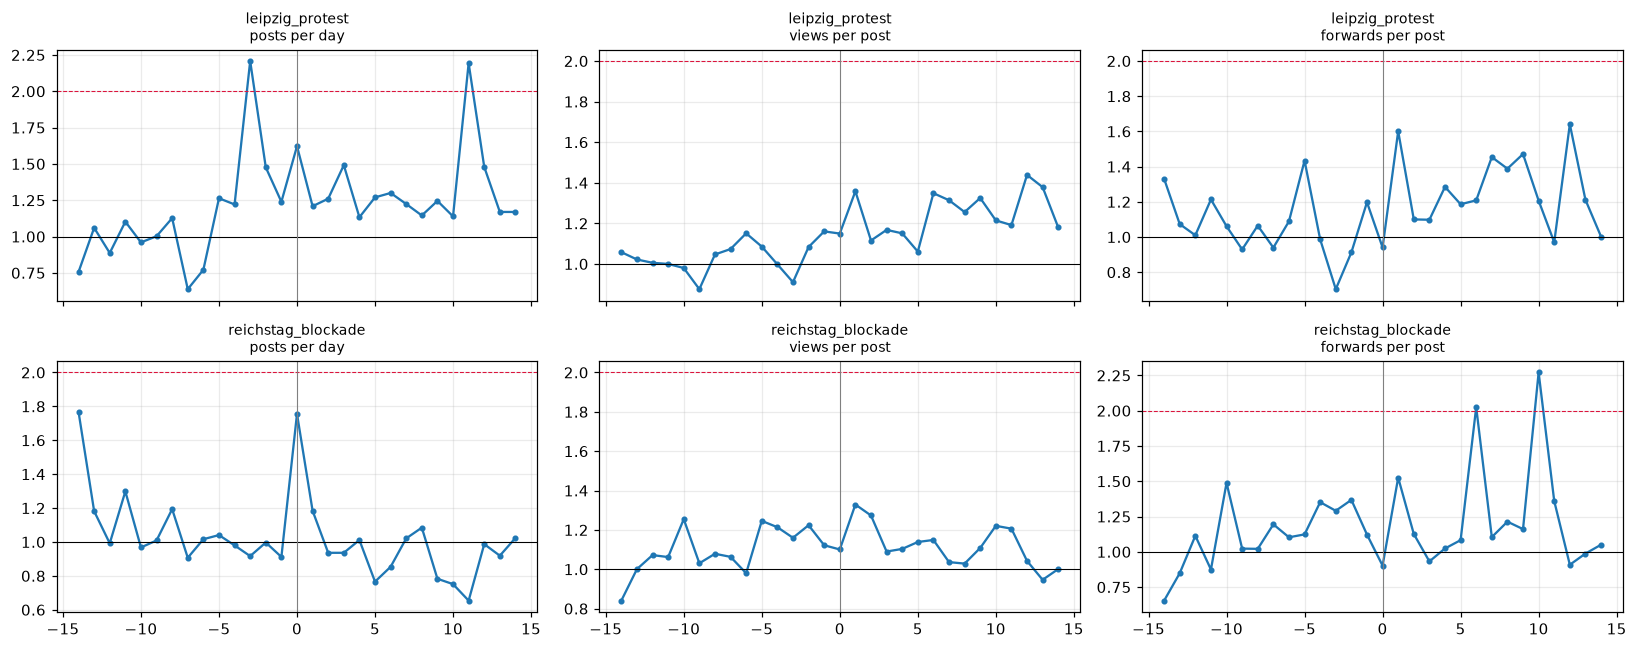

,event,series,baseline,peak_ratio,peak_gt_2x,ratio_T+12..14,placebo_p_peak,placebo_median_peak
0,leipzig_protest,posts per day,329.2,1.62,False,1.27,0.009,1.11
1,leipzig_protest,views per post,40888.1,1.36,False,1.33,0.041,1.06
2,leipzig_protest,forwards per post,223.6,1.60,False,1.28,0.036,1.13
3,reichstag_blockade,posts per day,411.3,1.76,False,0.98,0.007,1.11
4,reichstag_blockade,views per post,44262.0,1.33,False,1.00,0.052,1.06
5,reichstag_blockade,forwards per post,240.5,1.53,False,0.98,0.050,1.13


In [4]:
h2_rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
for i, name in enumerate(["leipzig_protest", "reichstag_blockade"]):
    T = ev.get(name)
    if T is None:
        print(name, "has no date"); continue
    for j, (lab, s) in enumerate([("posts per day", series_for(df, "n")), ("views per post", per_post(df, "views_sum")), ("forwards per post", per_post(df, "forwards_sum"))]):
        try:
            w = event_window(s, T)
            pt = placebo_test(s, T, other_events=[d for d in ALL_EVENT_DATES if d != T])
            pl_late = placebo_test(s, T, stat="late_ratio", other_events=[d for d in ALL_EVENT_DATES if d != T])
        except Exception as e:
            print(name, lab, "skipped:", e); continue
        h2_rows.append({"event": name, "series": lab, "baseline": round(w["baseline"], 1), "peak_ratio": round(w["peak_ratio"], 2),
                        "peak_gt_2x": w["peak_ratio"] > 2, "ratio_T+12..14": round(w["late_ratio"], 2),
                        "placebo_p_peak": round(pt["p_one_sided"], 3), "placebo_median_peak": round(pt["placebo_median"], 2)})
        record("H2", f"{name}: {lab}, peak ratio T-1..T+2 (placebo)", w["peak_ratio"], pt["p_one_sided"], "plan expects > 2.0 and ratio ~1 at T+14")
        ax = axes[i, j]; t = w["table"]; ax.plot(t["rel_day"], t["ratio"], marker="o", ms=3)
        ax.axhline(1, color="k", lw=0.7); ax.axhline(2, color="crimson", lw=0.7, ls="--"); ax.axvline(0, color="grey", lw=0.7)
        ax.set_title(f"{name}\n{lab}", fontsize=9)
plt.tight_layout(); savefig("04_H2"); plt.show()
pd.DataFrame(h2_rows)

## H3 - Geopolitical pivot
*In the 21 days after 2022-02-24 the share of posts with COVID keywords falls by more than 60 %, mirrored by a rise in Ukraine/Russia/NATO keywords.*

> **Literature.** Plan: [11] Boell Foundation, *Democratic Corrosion at the Heart of Europe* (Covid-19, the war in Ukraine). Method: Killick et al. 2012 (change-point detection); Bernal et al. 2017 (interrupted time series).


Shares are among posts **with text**. `_core` = the example terms named in the plan, `_extended` = broader lists
(edit in `config/keywords.json`). Also: a single change-point search on the daily share, and a per-channel view.

In [5]:
T = ev["ukraine_invasion"]
tx = df.filter(pl.col("has_text"))
pre = tx.filter((pl.col("day") >= T - timedelta(days=21)) & (pl.col("day") < T))
post = tx.filter((pl.col("day") >= T) & (pl.col("day") < T + timedelta(days=21)))
rows = []
for name in ("covid_core", "covid_extended", "ukraine_core", "ukraine_extended"):
    col = f"kw_{name}"
    r = two_proportions(int(pre[col].sum()), pre.height, int(post[col].sum()), post.height)
    rows.append({"list": name, "n_before": pre.height, "n_after": post.height, "share_before": round(r["share_before"], 4),
                 "share_after": round(r["share_after"], 4), "relative_change": round(r["relative_change"], 3), "p": r["p"]})
    record("H3", f"relative change of the share of text posts with {name}, 21d after vs before invasion", r["relative_change"], r["p"],
           "plan expects covid <= -0.60, ukraine up")
pd.DataFrame(rows)

,list,n_before,n_after,share_before,share_after,relative_change,p
0,covid_core,7322,7796,0.0624,0.0335,-0.464,6.286472e-17
1,covid_extended,7322,7796,0.2968,0.1696,-0.429,9.807938e-77
2,ukraine_core,7322,7796,0.0419,0.1169,1.787,3.420679e-64
3,ukraine_extended,7322,7796,0.1076,0.3765,2.498,0.000000e+00


covid_extended: best single change point 2022-02-21 (explains 78% of the variance)
ukraine_extended: best single change point 2022-02-22 (explains 86% of the variance)


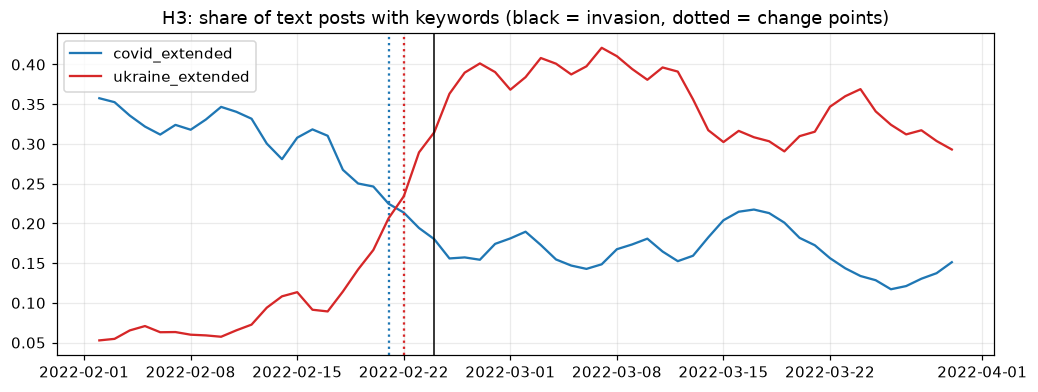

In [6]:
win = tx.filter((pl.col("day") >= date(2022, 2, 1)) & (pl.col("day") <= date(2022, 3, 31)))
fig, ax = plt.subplots(figsize=(11, 3.8))
for name, c in (("covid_extended", "tab:blue"), ("ukraine_extended", "tab:red")):
    s = (win.group_by("day").agg(pl.col(f"kw_{name}").mean().alias("share")).sort("day").to_pandas().set_index("day")["share"])
    s.index = pd.to_datetime(s.index)
    ax.plot(s.index, s.rolling(3, center=True).mean(), label=name, color=c)
    cp, gain = best_changepoint(s)
    ax.axvline(cp, color=c, ls=":"); print(f"{name}: best single change point {cp.date()} (explains {gain:.0%} of the variance)")
ax.axvline(pd.Timestamp(T), color="k", lw=1); ax.set_title("H3: share of text posts with keywords (black = invasion, dotted = change points)"); ax.legend()
savefig("04_H3"); plt.show()

In [7]:
per = (tx.filter(((pl.col("day") >= T - timedelta(days=21)) & (pl.col("day") < T + timedelta(days=21))))
         .with_columns((pl.col("day") >= T).alias("after"))
         .group_by("channel", "after").agg(pl.col("kw_covid_extended").mean().alias("covid_share"), pl.len().alias("n"))
         .to_pandas().pivot(index="channel", columns="after", values="covid_share"))
per.columns = ["before", "after"] if len(per.columns) == 2 else per.columns
if {"before", "after"} <= set(per.columns):
    per["change"] = per["after"] / per["before"] - 1
    print(f"{(per['change'] <= -0.6).sum()} of {per['change'].notna().sum()} channels with COVID share down >= 60 %")
    per.round(3).sort_values("change")

0 of 14 channels with COVID share down >= 60 %


## H4 - Deplatforming displacement
*After the YouTube ban of Querdenken actors, their Telegram channels show a permanent step increase in posting volume.*

> **Literature.** Plan: [10] Amadeu Antonio Stiftung, *Netzkulturen und Plattformpolitiken*. Displacement / migration to Telegram: Rogers 2020. **Caveat from the literature:** studies of deplatforming (Jhaver et al. 2021; Horta Ribeiro et al. 2021; Chandrasekharan et al. 2017) mostly find *reduced* reach / activity after bans and migrations, with the remaining audience more radical - so a permanent *increase* in volume is a bold prediction; the level-shift test below can come out either way.


The plan is ambiguous about the date (text: late 2020 / early 2021; table: Phase 4 from 2021-03-01), so
`youtube_deplatforming` in `config/events.csv` is **empty - fill in the date you pre-register**. Cohort = channel group
`deplatformed` in `config/channel_groups.csv` (all channels if the group does not exist). Subscriber growth, the
other half of H4, is not in the exported data.

In [8]:
try:
    T = ev.get("youtube_deplatforming")
    if T is None:
        raise ValueError("no date for youtube_deplatforming in config/events.csv")
    frame, chans = group_frame("deplatformed")
    if not chans:
        frame, chans = df, df["channel"].unique().to_list(); print("no group 'deplatformed' - using all channels")
    s = series_for(frame, "n")
    r = its_fit(s, T, pre_days=90, post_days=90)
    print(f"level shift at T: x{r['level_ratio']:.2f} (95% CI {r['level_ci'][0]:.2f}-{r['level_ci'][1]:.2f}), p={r['p_level']:.3g}; "
          f"slope change {r['slope_change_pct_per_day']:+.2f}% per day (p={r['p_slope']:.3g}); {len(chans)} channels")
    record("H4", f"ITS level shift in posts/day at {T} ({len(chans)} channels)", r["level_ratio"], r["p_level"], "plan expects a permanent positive step (ratio > 1)")
    fig, ax = plt.subplots(figsize=(11, 3.5)); ax.plot(r["observed"], lw=0.7, alpha=0.6); ax.plot(r["fitted"], color="crimson")
    ax.axvline(r["event_day"], color="k"); ax.set_title("H4: posts per day with ITS fit"); savefig("04_H4"); plt.show()
except Exception as e:
    print("H4 skipped:", e)

H4 skipped: no date for youtube_deplatforming in config/events.csv


## H5 - QAnon dissolution
*After the US inauguration (2021-01-20) engagement per post in German QAnon channels drops by more than 50 % permanently.*

> **Literature.** Plan: no citation given. Background: Amadeu Antonio Stiftung 2020, *QAnon in Deutschland* (plan [2]); failed prophecy and cognitive dissonance: Festinger, Riecken & Schachter 1956. Method: Bernal et al. 2017.


Cohort = channel group `qanon`. Engagement = views, forwards and reactions per post (daily mean, log scale model)
and the posting volume itself. Comments are not part of the export.

In [9]:
try:
    T = ev["us_inauguration"]
    frame, chans = group_frame("qanon")
    if not chans:
        raise ValueError("no channels in group 'qanon' (config/channel_groups.csv)")
    out = []
    for lab, s, kind in (("views per post", per_post(frame, "views_sum"), "log"), ("forwards per post", per_post(frame, "forwards_sum"), "log"),
                         ("posts per day", series_for(frame, "n"), "count")):
        try:
            r = its_fit(s, T, pre_days=60, post_days=60, kind=kind)
        except Exception as e:
            print(lab, "skipped:", e); continue
        out.append({"series": lab, "level_ratio": round(r["level_ratio"], 3), "ci_low": round(r["level_ci"][0], 3), "ci_high": round(r["level_ci"][1], 3),
                    "p_level": r["p_level"], "slope_change_%/day": round(r["slope_change_pct_per_day"], 2), "p_slope": r["p_slope"], "days": r["n_days"]})
        record("H5", f"ITS level ratio of {lab} at inauguration ({len(chans)} channels)", r["level_ratio"], r["p_level"], "plan expects < 0.5")
    display(pd.DataFrame(out))
except Exception as e:
    print("H5 skipped:", e)

,series,level_ratio,ci_low,ci_high,p_level,slope_change_%/day,p_slope,days
0,views per post,0.961,0.787,1.174,0.699797,-1.05,0.003996,119
1,forwards per post,1.339,0.870,2.060,0.184412,-1.63,0.044891,119
2,posts per day,0.452,0.229,0.895,0.022583,-2.73,0.000003,120


## H6 - Coup-plot network silence
*After the Reichsbuerger raids (2022-12-07) posting volume in adjacent networks drops for about 7-10 days.*

> **Literature.** Plan: [9] Heyn 2025. Method: Bernal et al. 2017 (interrupted time series); Newey & West 1987.


Cohort = group `reichsbuerger`. Window as in the plan: 2022-11-15 to 2022-12-31. Only ~45 days, so confidence
intervals are wide - the simple before/after ratio is shown too.

In [10]:
try:
    T = ev["reichsbuerger_raid"]
    frame, chans = group_frame("reichsbuerger")
    if not chans:
        raise ValueError("no channels in group 'reichsbuerger'")
    s = series_for(frame, "n")
    r = its_fit(s, T, pre_days=(T - date(2022, 11, 15)).days, post_days=(date(2022, 12, 31) - T).days + 1)
    pre_m = s[pd.Timestamp(T) - pd.Timedelta(days=22): pd.Timestamp(T) - pd.Timedelta(days=1)].mean()
    post_m = s[pd.Timestamp(T): pd.Timestamp(T) + pd.Timedelta(days=9)].mean()
    print(f"{len(chans)} channels | level ratio {r['level_ratio']:.2f} (95% CI {r['level_ci'][0]:.2f}-{r['level_ci'][1]:.2f}), p={r['p_level']:.3g}")
    print(f"mean posts/day: 22 days before {pre_m:.1f} -> first 10 days after {post_m:.1f} (ratio {post_m / pre_m:.2f})")
    record("H6", f"ITS level ratio at raids ({len(chans)} channels)", r["level_ratio"], r["p_level"], "plan expects a drop (< 1) lasting 7-10 days")
    fig, ax = plt.subplots(figsize=(10, 3.4)); ax.plot(r["observed"], marker="o", ms=3); ax.plot(r["fitted"], color="crimson")
    ax.axvline(r["event_day"], color="k"); ax.set_title("H6: posts per day"); savefig("04_H6"); plt.show()
except Exception as e:
    print("H6 skipped:", e)

H6 skipped: no channels in group 'reichsbuerger'


## H7 - API paywall (X/Twitter)
Not testable with Telegram data: the hypothesis concerns data collected from the X API after 2023-02-09. Skipped by design.

> **Literature.** Plan: [14] (X's shift), [15] *RIP Twitter API* (research contributions), [16] CNET, [40] Dark Reading, [29] CJR Tow Center Q&A.


## H8 - Post-October-7 antisemitism surge
*In the 30 days after 2023-10-07 the incidence of the antisemitic-conspiracy keywords (list `antisemitic_h8`) exceeds every earlier 30-day window.*

> **Literature.** Plan: [17] Parlament Oesterreich, *Antisemitismus 2024*; [18] RIAS, *Politischer Antisemitismus in Deutschland seit dem 7. Oktober 2023*. Method: record / rank statistic against earlier windows.


Measured as the share of text posts containing a keyword in 30-day windows; the p-value is the share of earlier
windows at least as high (windows overlap, so read it as a rank, not an exact probability).

share of text posts with antisemitic_h8 keywords: window after 7 Oct = 0.0006; earlier 30-day windows: max 0.0026, median 0.0005; rank p=0.4009 (add-one, n=1346 windows)
highest of all earlier windows: False


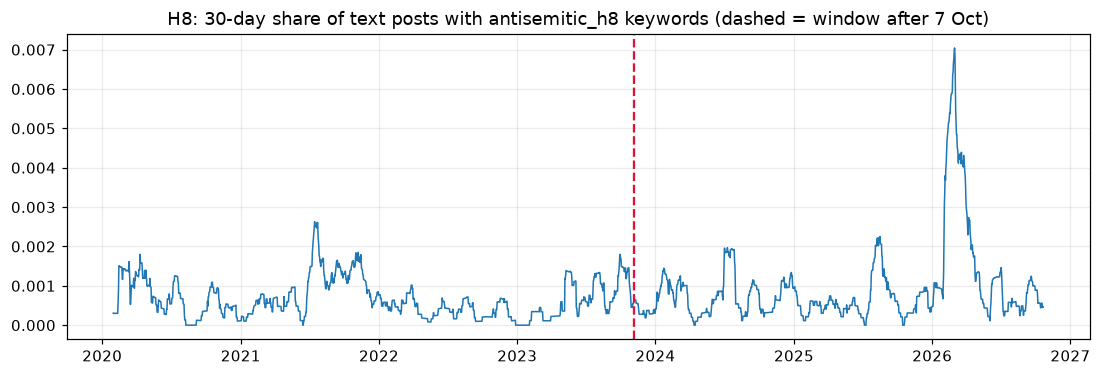

In [11]:
try:
    T = ev["hamas_attack"]
    tx = df.filter(pl.col("has_text"))
    k = series_for(tx.filter(pl.col("kw_antisemitic_h8")), "n"); n = series_for(tx, "n")
    if k.sum() < 20:
        raise ValueError(f"only {int(k.sum())} posts match the antisemitic_h8 keywords - too few for a 30-day window comparison")
    k30 = k.rolling(30).sum(); n30 = n.rolling(30).sum(); share = (k30 / n30.replace(0, np.nan))
    win_end = pd.Timestamp(T) + pd.Timedelta(days=29)          # the window T..T+29 ends here
    obs = share.loc[win_end]
    prior = share.loc[: pd.Timestamp(T) - pd.Timedelta(days=1)].dropna()
    prior = prior[n30.loc[prior.index] >= 200]                  # ignore windows with too few text posts
    p = float((1 + (prior >= obs).sum()) / (1 + len(prior))) if len(prior) else np.nan
    print(f"share of text posts with antisemitic_h8 keywords: window after 7 Oct = {obs:.4f}; earlier 30-day windows: "
          f"max {prior.max():.4f}, median {prior.median():.4f}; rank p={p:.4f} (add-one, n={len(prior)} windows)")
    print("highest of all earlier windows:", bool(obs > prior.max()))
    record("H8", "share of text posts with antisemitic_h8 keywords, 30d after 7 Oct vs all earlier 30d windows (rank)", float(obs / prior.median()) if prior.median() > 0 else float("nan"), p,
           "plan expects the post-7-Oct window to be the maximum; estimate = ratio to median earlier window")
    fig, ax = plt.subplots(figsize=(12, 3.6)); ax.plot(share.index, share, lw=1); ax.axvline(pd.Timestamp(T) + pd.Timedelta(days=29), color="crimson", ls="--")
    ax.set_title("H8: 30-day share of text posts with antisemitic_h8 keywords (dashed = window after 7 Oct)"); savefig("04_H8"); plt.show()
except Exception as e:
    print("H8 skipped:", e)

## H9 - Remigration backlash
*After the Correctiv report (2024-01-10) the terms in `remigration_h9` rise and stay elevated for 30+ days - a slower decay than the H2 events.*

> **Literature.** Plan: [19] CORRECTIV, *Geheimplan gegen Deutschland* (2024-01-10). Method: MacKinlay 1997 (event windows); placebo inference (Young 2019).


Ratio to the pre-event baseline (T-21..T-8) at T+1..T+2 (peak), around T+14 and around T+30..T+45; the placebo test asks how
often random days show a sustained (T+30..T+45) elevation this large. The H2 events (posts per day) are shown for comparison.

baseline 0.36 posts/day | peak over T..T+14 x30.80 (placebo p=0.014) | T+12..14 x10.27 | T+30..45 x4.20 (placebo p=0.084)


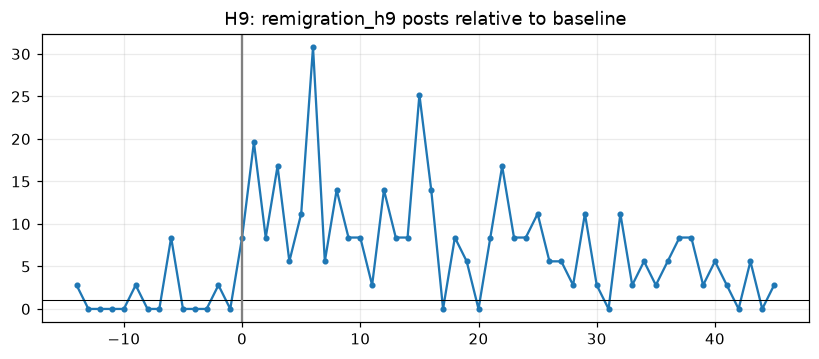

,event,T+12..14,T+30..45
0,leipzig_protest,1.27,1.06
1,reichstag_blockade,0.98,0.74


In [12]:
try:
    T = ev["correctiv_report"]
    s9 = series_for(df.filter(pl.col("kw_remigration_h9")), "n")
    w = event_window(s9, T, pre=14, post=45, peak=(0, 14), late=(30, 45))
    pt_peak = placebo_test(s9, T, stat="peak_ratio", other_events=[d for d in ALL_EVENT_DATES if d != T], peak=(0, 14), late=(30, 45))
    pt_late = placebo_test(s9, T, stat="late_ratio", other_events=[d for d in ALL_EVENT_DATES if d != T], peak=(0, 14), late=(30, 45))
    t = w["table"].set_index("rel_day")["ratio"]
    print(f"baseline {w['baseline']:.2f} posts/day | peak over T..T+14 x{w['peak_ratio']:.2f} (placebo p={pt_peak['p_one_sided']:.3f}) | "
          f"T+12..14 x{t.loc[12:14].mean():.2f} | T+30..45 x{w['late_ratio']:.2f} (placebo p={pt_late['p_one_sided']:.3f})")
    record("H9", "remigration_h9 posts: ratio T+30..45 vs baseline (placebo)", w["late_ratio"], pt_late["p_one_sided"], "plan expects a sustained plateau (> 1) rather than a sharp decay")
    comp = []
    for name in ("leipzig_protest", "reichstag_blockade"):
        if name in ev:
            try:
                wc = event_window(series_for(df, "n"), ev[name], pre=14, post=45, peak=(0, 14), late=(30, 45))
                tc = wc["table"].set_index("rel_day")["ratio"]
                comp.append({"event": name, "T+12..14": round(tc.loc[12:14].mean(), 2), "T+30..45": round(wc["late_ratio"], 2)})
            except Exception as e:
                print(name, "skipped:", e)
    fig, ax = plt.subplots(figsize=(9, 3.4)); ax.plot(t.index, t.values, marker="o", ms=3); ax.axhline(1, color="k", lw=0.7); ax.axvline(0, color="grey")
    ax.set_title("H9: remigration_h9 posts relative to baseline"); savefig("04_H9"); plt.show()
    display(pd.DataFrame(comp))
except Exception as e:
    print("H9 skipped:", e)

## H10 - WHO treaty disinformation
*Around the World Health Assembly / 2024-06-01 the terms in `who_h10` ("Great Reset", "WHO", "Diktatur") co-occur more strongly.*

> **Literature.** Plan: [22] outcomes of the 77th World Health Assembly; [23] *WHO Pandemic Agreement*, International Legal Materials. Method: Jaccard 1912 (co-occurrence similarity).


Jaccard similarity of two terms = posts with both / posts with either, in a 29-day window ending T+14. The placebo
distribution is the same statistic in all other 29-day windows (at least 20 posts with either term, not within 30
days of T+14). "WHO" is matched case-sensitively.

In [ ]:
try:
    import itertools
    T = ev["who_pandemic_agreement"]
    terms = KW["who_h10"]; names = [t.lstrip("=") for t in terms]
    tx = df.filter(pl.col("has_text")).with_columns([keyword_flag([t]).alias(f"t{i}") for i, t in enumerate(terms)])
    out = []
    for (i, a), (j, b) in itertools.combinations(enumerate(names), 2):
        both = tx.filter(pl.col(f"t{i}") & pl.col(f"t{j}"))
        either = tx.filter(pl.col(f"t{i}") | pl.col(f"t{j}"))
        sb, se = series_for(both, "n").rolling(29).sum(), series_for(either, "n").rolling(29).sum()
        jac = (sb / se.replace(0, np.nan)).where(se >= 20)
        at = pd.Timestamp(T) + pd.Timedelta(days=14)
        obs = jac.loc[at]
        ref = jac.drop(index=jac.index[abs((jac.index - at).days) <= 30]).dropna()
        p = float((1 + (ref >= obs).sum()) / (1 + len(ref))) if pd.notna(obs) and len(ref) else np.nan
        out.append({"pair": f"{a} + {b}", "jaccard_window": round(obs, 4) if pd.notna(obs) else None, "placebo_median": round(ref.median(), 4), "placebo_p95": round(ref.quantile(.95), 4), "p_one_sided": round(p, 3), "windows": len(ref)})
        if pd.notna(p):
            record("H10", f"Jaccard {a} + {b}, window ending T+14 (placebo)", float(obs), p, "plan expects a high co-occurrence")
    display(pd.DataFrame(out))
except Exception as e:
    print("H10 skipped:", e)

## H11 - Telegram moderation chilling effect
*After 2024-09-23 violent-extremist channels reduce posting volume relative to a control group of non-violent conspiracy channels.*

> **Literature.** Plan: [1] REDACT, *Report on Conspiracy Theories in the Online ... (DACH)*; [25] Android Authority on Telegram's data-sharing change; [26] Cyberint Telegram report. Method: Wooldridge 2023 (Poisson difference-in-differences); Cameron & Miller 2015 (few-cluster problem); Young 2019 (randomization inference).


Cohorts: groups `violent_extremist` (treated) and `general` (control) in `config/channel_groups.csv`. **I did not
classify your channels - you have to.** Weekly counts, 12 weeks before/after. Two estimates:
a Poisson difference-in-differences with channel and week fixed effects, and an exact **randomization test**
(reassign the treated label among all channels). With only a handful of channels the second one is the one to trust;
the smallest possible p-value is 1 / number of possible assignments.

In [ ]:
try:
    T = ev["telegram_ip_policy"]
    tr, ctl = channels_of(df, GROUPS.get("violent_extremist", [])), channels_of(df, GROUPS.get("general", []))
    if not tr or not ctl:
        raise ValueError("need channels in both groups 'violent_extremist' and 'general' (config/channel_groups.csv)")
    weeks = 12
    lo, hi = pd.Timestamp(T) - pd.Timedelta(weeks=weeks), pd.Timestamp(T) + pd.Timedelta(weeks=weeks)
    dcw = (daily_counts(df.filter(pl.col("channel").is_in(tr + ctl)))
           .with_columns(pl.col("day").dt.truncate("1w").alias("week")).group_by("channel", "week").agg(pl.col("n").sum().alias("y")).to_pandas())
    dcw["week"] = pd.to_datetime(dcw["week"]); dcw = dcw[(dcw["week"] >= lo) & (dcw["week"] < hi)]
    dcw["treated"] = dcw["channel"].isin(tr).astype(int)
    r = did_ppml(dcw, T); rnd = did_randomization(dcw, T)
    print(f"treated {len(tr)} / control {len(ctl)} channels")
    print(f"Poisson DiD: rate ratio {r['rate_ratio']:.2f} (95% CI {r['ci'][0]:.2f}-{r['ci'][1]:.2f}), cluster p={r['p']:.3g}  {r['warning']}")
    print(f"Randomization: ratio of ratios {rnd['ratio_of_ratios']:.2f}, p={rnd['p']:.3f} ({rnd['n_assignments']} assignments, exact={rnd['exact']})")
    record("H11", f"DiD violent vs control, ratio of ratios, randomization test ({len(tr)} vs {len(ctl)} channels)", rnd["ratio_of_ratios"], rnd["p"], "plan expects < 1 for violent channels")
    g = dcw.groupby(["week", "treated"])["y"].sum().unstack()
    base = g[g.index < pd.Timestamp(T)].mean()
    fig, ax = plt.subplots(figsize=(10, 3.5)); (g / base * 100).plot(ax=ax, marker="o", ms=3); ax.axvline(pd.Timestamp(T), color="k")
    ax.legend(["control", "violent_extremist"]); ax.set_ylabel("posts, % of pre-period weekly mean"); ax.set_title("H11: weekly posts by group"); savefig("04_H11"); plt.show()
except Exception as e:
    print("H11 skipped:", e)

## H12 - Snap-election mobilization
*In the 60 days before the 2025-02-23 federal election posting density rises steadily, driven by claims of election fraud.*

> **Literature.** Plan: [28] IG Metall, *How the federal election works*; [27] Bundeswahlleiterin. Method: Bernal et al. 2017 (ITS); Newey & West 1987.


Interrupted time series with the break at T-60 on the preceding 60 days: is the slope in the last 60 days steeper
than before? (Level and slope change.) The coalition collapse (2024-11-06) falls into the comparison window.
The keyword list `election_fraud_h12` is analysed the same way.

In [ ]:
try:
    T = ev["snap_election"]
    brk = pd.Timestamp(T) - pd.Timedelta(days=60)
    out = []
    for lab, s in (("all posts per day", series_for(df, "n")), ("election_fraud_h12 posts per day", series_for(df.filter(pl.col("kw_election_fraud_h12")), "n"))):
        try:
            r = its_fit(s, brk, pre_days=60, post_days=60)
        except Exception as e:
            print(lab, "skipped:", e); continue
        out.append({"series": lab, "level_ratio": round(r["level_ratio"], 3), "p_level": r["p_level"], "slope_change_%/day": round(r["slope_change_pct_per_day"], 2), "p_slope": r["p_slope"]})
        record("H12", f"ITS slope change in the 60 days before the election: {lab}", r["slope_change_pct_per_day"], r["p_slope"], "plan expects a positive slope change (growth towards T)")
        if lab.startswith("all"):
            fig, ax = plt.subplots(figsize=(10, 3.4)); ax.plot(r["observed"], lw=0.8); ax.plot(r["fitted"], color="crimson")
            ax.axvline(brk, color="k", ls=":"); ax.axvline(pd.Timestamp(T), color="k"); ax.set_title("H12: posts per day (dotted = T-60, solid = election)"); savefig("04_H12"); plt.show()
    display(pd.DataFrame(out))
except Exception as e:
    print("H12 skipped:", e)

## Summary table

All recorded tests with Holm-adjusted p-values across the whole family. `estimate` is a ratio (1 = no change) or a
percent slope change as described in `test`; `note` repeats what the plan predicted. Statistical significance is not
the same as a large effect - look at the estimate and the plots, and remember the survivor-bias and keyword
caveats from the plan.

In [ ]:
res = holm_table(RESULTS)
res["estimate"] = res["estimate"].astype(float).round(3)
res.to_csv(FIG / "hypothesis_results.csv", index=False)
pd.set_option("display.max_colwidth", 90, "display.width", 200)
res

## References

**From the research plan's works-cited list** (numbering as in the plan; titles abbreviated there as well):
[1] REDACT, report on conspiracy theories online (DACH) &middot; [2] Amadeu Antonio Stiftung, *QAnon in Deutschland* &middot;
[4] Jahn 2022, politics and lockdown regulations in 35 advanced democracies, *Int. Political Science Review* &middot;
[8]/[35] *Spreading the disease: Protest in times of pandemics* &middot;
[9] Heyn 2025, Telegram-YouTube pipeline (MPI LGCL) &middot; [10] *Wissenschafft Demokratie: Netzkulturen und Plattformpolitiken* &middot;
[11] Boell Foundation, *Democratic Corrosion at the Heart of Europe* &middot; [14] *X's Shift* &middot; [15] *RIP Twitter API* &middot; [16] CNET &middot;
[17] Parlament Oesterreich, *Antisemitismus 2024* &middot; [18] RIAS Bundesverband &middot; [19] CORRECTIV, *Geheimplan gegen Deutschland* &middot;
[22] 77th World Health Assembly outcomes &middot; [23] *WHO Pandemic Agreement*, Int. Legal Materials &middot; [25] Android Authority, Telegram data sharing &middot;
[26] Cyberint, Telegram report &middot; [27] Bundeswahlleiterin &middot; [28] IG Metall on the 2025 federal election &middot; [29] CJR Tow Center &middot;
[37] Mandl 2026, systematic survey of computational narrative analysis &middot; [39] WIDER WP 2024/14 &middot; [40] Dark Reading.

**Methods and theory** (details written from memory - **only Wooldridge 2023 and Rogers 2020 were checked online; verify volume / page numbers before citing**):

* Bernal, J. L., Cummins, S. & Gasparrini, A. (2017). Interrupted time series regression for the evaluation of public health interventions: a tutorial. *Int. J. Epidemiology* 46(1), 348-355.
* Cameron, A. C. & Miller, D. L. (2015). A practitioner's guide to cluster-robust inference. *J. Human Resources* 50(2), 317-372.
* Chandrasekharan, E. et al. (2017). You can't stay here: the efficacy of Reddit's 2015 ban examined through hate speech. *PACMHCI (CSCW)* 1, 31.
* Festinger, L., Riecken, H. W. & Schachter, S. (1956). *When Prophecy Fails*. University of Minnesota Press.
* Hale, T. et al. (2021). A global panel database of pandemic policies (Oxford COVID-19 Government Response Tracker). *Nature Human Behaviour* 5, 529-538.
* Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scand. J. Statistics* 6(2), 65-70.
* Horta Ribeiro, M. et al. (2021). Do platform migrations compromise content moderation? Evidence from r/The_Donald and r/Incels. *PACMHCI (CSCW)* 5, 316.
* Jaccard, P. (1912). The distribution of the flora in the alpine zone. *New Phytologist* 11(2), 37-50.
* Jhaver, S. et al. (2021). Evaluating the effectiveness of deplatforming as a moderation strategy on Twitter. *PACMHCI (CSCW2)* 5, 381.
* Killick, R., Fearnhead, P. & Eckley, I. A. (2012). Optimal detection of changepoints with a linear computational cost. *JASA* 107(500), 1590-1598.
* Lange, M. & Monscheuer, O. (2021). Spreading the disease: Protest in times of pandemics. ZEW Discussion Paper 21-009.
* MacKinlay, A. C. (1997). Event studies in economics and finance. *J. Economic Literature* 35(1), 13-39.
* Newey, W. K. & West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica* 55(3), 703-708.
* Rogers, R. (2020). Deplatforming: Following extreme Internet celebrities to Telegram and alternative social media. *European J. Communication* 35(3), 213-229.
* Santos Silva, J. M. C. & Tenreyro, S. (2006). The log of gravity. *Review of Economics and Statistics* 88(4), 641-658.
* Wooldridge, J. M. (2023). Simple approaches to nonlinear difference-in-differences with panel data. *The Econometrics Journal* 26(3), C31-C66.
* Young, A. (2019). Channeling Fisher: randomization tests and the statistical insignificance of seemingly significant experimental results. *Quarterly J. Economics* 134(2), 557-598.

**Notes on sources**

* The plan states a "35.9 % regional spike in infection rates" after the Leipzig protest and attributes it to its reference 8. The matching study is
  Lange & Monscheuer (ZEW DP 21-009); I could **not** confirm the 35.9 % figure or that the estimate is Leipzig-only - check the paper before quoting it.
* The plan's expected direction for H4 (increase after deplatforming) contrasts with the deplatforming literature cited under H4.
* No published study is known to me that tests H5 on German QAnon channels; the plan gives no source for it.